**Import libraries**

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

**Load the unclean CSV**

In [16]:
df = pd.read_csv("Tetuan_City_power_consumption_unclean.csv")

print("Original shape:", df.shape)
print("\nOriginal columns:")
print(df.columns.tolist())

display(df.head())

Original shape: (52678, 11)

Original columns:
['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2  Power Consumption', 'Zone 3  Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,NaN,15.74,74.8,0.082,0.059,0.07,36535.38462,29584.71074,15984.57831,NaN,NaN
1,NaN,15.28,58.26,0.08,512.4,158.3,33776.42586,26853.63608,10222.32893,NaN,NaN
2,NaN,16.3,35.46,0.09,436.4,476.3,30552.51064,19485.36585,14696.12903,NaN,NaN
3,02/05/2017 01:20,8.28,50.62,0.096,0.088,0.078,25175.59322,14877.81155,16492.70352,NaN,NaN
4,NaN,12.76,62.5,4.925,0.157,0.115,40270.76923,33567.76860,17615.42169,NaN,NaN


**Clean the unclean data**

In [22]:
# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Combine columns that now have the same name
cleaned_columns = {}

for name in dict.fromkeys(df.columns):
    matching = df.loc[:, df.columns == name]

    if matching.shape[1] == 1:
        cleaned_columns[name] = matching.iloc[:, 0]
    else:
        cleaned_columns[name] = matching.bfill(axis=1).iloc[:, 0]

df = pd.DataFrame(cleaned_columns)

# Required columns
features = [
    "Temperature",
    "Humidity",
    "Wind Speed",
    "general diffuse flows",
    "diffuse flows"
]

targets = [
    "Zone 1 Power Consumption",
    "Zone 2 Power Consumption",
    "Zone 3 Power Consumption"
]

required_columns = features + targets

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

# Convert feature and target values to numbers
for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace infinite values with missing values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Target values must exist, but feature values may be missing
df.dropna(subset=targets, inplace=True)
df.reset_index(drop=True, inplace=True)

print("Shape after cleaning:", df.shape)
print("\nMissing values in features:")
print(df[features].isnull().sum())

print("\nMissing target values:")
print(df[targets].isnull().sum())

display(df.head())

Shape after cleaning: (51528, 9)

Missing values in features:
Temperature              873
Humidity                 872
Wind Speed               870
general diffuse flows    868
diffuse flows            873
dtype: int64

Missing target values:
Zone 1 Power Consumption    0
Zone 2 Power Consumption    0
Zone 3 Power Consumption    0
dtype: int64


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,NaN,15.74,74.80,0.082,0.059,0.070,36535.38462,29584.71074,15984.57831
1,NaN,15.28,58.26,0.080,512.400,158.300,33776.42586,26853.63608,10222.32893
2,NaN,16.30,35.46,0.090,436.400,476.300,30552.51064,19485.36585,14696.12903
3,02/05/2017 01:20,8.28,50.62,0.096,0.088,0.078,25175.59322,14877.81155,16492.70352
4,NaN,12.76,62.50,4.925,0.157,0.115,40270.76923,33567.76860,17615.42169


**Check that enough rows remain**

In [23]:
print("Available rows:", len(df))

if len(df) < 10:
    raise ValueError(
        "Too few rows remain. Check the CSV columns and target values."
    )

print("Dataset is ready for classification.")

Available rows: 51528
Dataset is ready for classification.


**Split the data into training and testing sets**

In [25]:
X = df[features].copy()

train_indices, test_indices = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42
)

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 41222
Testing records: 10306


**Convert consumption values into categories**

In [28]:
y_train_dict = {}
y_test_dict = {}
thresholds = {}

for target in targets:

    train_values = df[target].iloc[train_indices]
    test_values = df[target].iloc[test_indices]

    low_threshold = train_values.quantile(0.33)
    high_threshold = train_values.quantile(0.67)

    if low_threshold >= high_threshold:
        raise ValueError(
            f"Cannot create three categories for {target}. "
            "Check whether its values are mostly identical."
        )

    thresholds[target] = (low_threshold, high_threshold)

    y_train_dict[target] = np.select(
        [
            train_values <= low_threshold,
            train_values <= high_threshold
        ],
        [
            "LOW",
            "MEDIUM"
        ],
        default="HIGH"
    )

    y_test_dict[target] = np.select(
        [
            test_values <= low_threshold,
            test_values <= high_threshold
        ],
        [
            "LOW",
            "MEDIUM"
        ],
        default="HIGH"
    )

    print(f"\n{target}")
    print("LOW threshold:", round(low_threshold, 2))
    print("HIGH threshold:", round(high_threshold, 2))
    print("Training categories:")
    print(pd.Series(y_train_dict[target]).value_counts())


Zone 1 Power Consumption
LOW threshold: 28469.08
HIGH threshold: 35502.43
Training categories:
MEDIUM    14017
LOW       13603
HIGH      13602
Name: count, dtype: int64

Zone 2 Power Consumption
LOW threshold: 18224.02
HIGH threshold: 23165.41
Training categories:
MEDIUM    14016
LOW       13603
HIGH      13603
Name: count, dtype: int64

Zone 3 Power Consumption
LOW threshold: 14307.47
HIGH threshold: 18938.18
Training categories:
MEDIUM    14019
LOW       13604
HIGH      13599
Name: count, dtype: int64


**Train the Random Forest classification models**

In [32]:
classification_models = {}

os.makedirs("models", exist_ok=True)

for target in targets:

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model.fit(X_train, y_train_dict[target])

    classification_models[target] = model

    filename = (
        target.lower()
        .replace(" ", "_")
        + "_classifier.pkl"
    )

    joblib.dump(model, os.path.join("models", filename))

    print(target, "model trained and saved.")

Zone 1 Power Consumption model trained and saved.
Zone 2 Power Consumption model trained and saved.
Zone 3 Power Consumption model trained and saved.


**Calculate classification accuracy**

In [33]:
results = []
predictions = {}

for target in targets:

    y_actual = y_test_dict[target]

    y_pred = classification_models[target].predict(X_test)
    predictions[target] = y_pred

    accuracy = accuracy_score(y_actual, y_pred)
    precision = precision_score(
        y_actual, y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_actual, y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_actual, y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Zone": target,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1 Score (%)": round(f1 * 100, 2)
    })

accuracy_df = pd.DataFrame(results)

print("CLASSIFICATION PERFORMANCE")
display(accuracy_df)

CLASSIFICATION PERFORMANCE


,Zone,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Zone 1 Power Consumption,76.25,76.28,76.25,76.23
1,Zone 2 Power Consumption,72.60,72.61,72.60,72.56
2,Zone 3 Power Consumption,75.20,75.17,75.20,75.18


**Show the detailed report for each zone**

In [35]:
for target in targets:

    print("\n", "=" * 50)
    print(target)
    print("=" * 50)

    print(
        classification_report(
            y_test_dict[target],
            predictions[target],
            labels=["LOW", "MEDIUM", "HIGH"],
            zero_division=0
        )
    )


Zone 1 Power Consumption
              precision    recall  f1-score   support

         LOW       0.75      0.80      0.77      3412
      MEDIUM       0.77      0.75      0.76      3479
        HIGH       0.76      0.74      0.75      3415

    accuracy                           0.76     10306
   macro avg       0.76      0.76      0.76     10306
weighted avg       0.76      0.76      0.76     10306


Zone 2 Power Consumption
              precision    recall  f1-score   support

         LOW       0.72      0.76      0.74      3400
      MEDIUM       0.73      0.68      0.70      3576
        HIGH       0.73      0.74      0.73      3330

    accuracy                           0.73     10306
   macro avg       0.73      0.73      0.73     10306
weighted avg       0.73      0.73      0.73     10306


Zone 3 Power Consumption
              precision    recall  f1-score   support

         LOW       0.75      0.77      0.76      3435
      MEDIUM       0.72      0.70      0.71      35

**Plot accuracy**

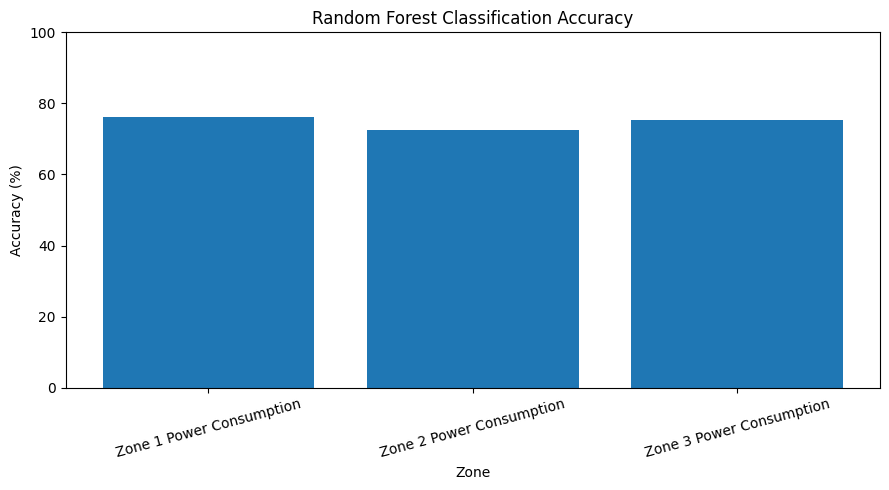

In [37]:
plt.figure(figsize=(9, 5))

plt.bar(
    accuracy_df["Zone"],
    accuracy_df["Accuracy (%)"]
)

plt.title("Random Forest Classification Accuracy")
plt.xlabel("Zone")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Display confusion matrices**

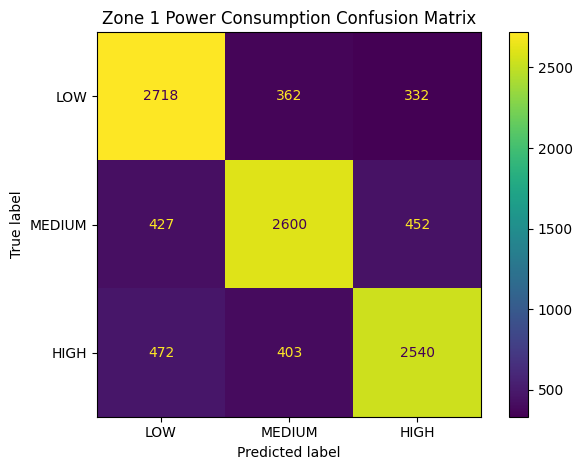

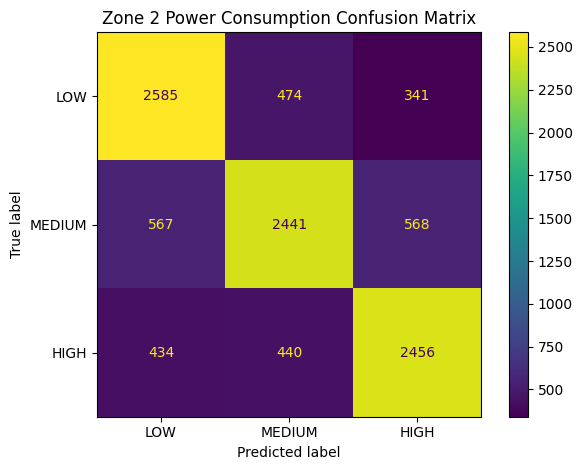

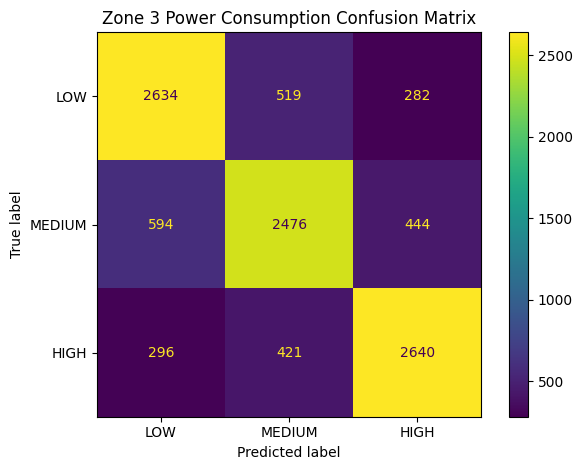

In [39]:
for target in targets:

    ConfusionMatrixDisplay.from_predictions(
        y_test_dict[target],
        predictions[target],
        labels=["LOW", "MEDIUM", "HIGH"],
        display_labels=["LOW", "MEDIUM", "HIGH"]
    )

    plt.title(target + " Confusion Matrix")
    plt.tight_layout()
    plt.show()

**Compare actual and predicted categories**

In [41]:
for target in targets:

    comparison_df = pd.DataFrame({
        "Actual Category": y_test_dict[target],
        "Predicted Category": predictions[target]
    })

    comparison_df["Correct"] = (
        comparison_df["Actual Category"]
        == comparison_df["Predicted Category"]
    )

    print("\n", target)
    display(comparison_df.head(15))


 Zone 1 Power Consumption


,Actual Category,Predicted Category,Correct
0,HIGH,LOW,False
1,HIGH,MEDIUM,False
2,MEDIUM,MEDIUM,True
3,HIGH,MEDIUM,False
4,MEDIUM,HIGH,False
5,HIGH,HIGH,True
6,LOW,LOW,True
7,HIGH,LOW,False
8,HIGH,HIGH,True
9,MEDIUM,MEDIUM,True



 Zone 2 Power Consumption


,Actual Category,Predicted Category,Correct
0,HIGH,LOW,False
1,MEDIUM,MEDIUM,True
2,MEDIUM,MEDIUM,True
3,MEDIUM,MEDIUM,True
4,MEDIUM,MEDIUM,True
5,HIGH,HIGH,True
6,LOW,LOW,True
7,HIGH,LOW,False
8,HIGH,HIGH,True
9,MEDIUM,MEDIUM,True



 Zone 3 Power Consumption


,Actual Category,Predicted Category,Correct
0,MEDIUM,MEDIUM,True
1,MEDIUM,LOW,False
2,MEDIUM,MEDIUM,True
3,MEDIUM,MEDIUM,True
4,HIGH,HIGH,True
5,HIGH,HIGH,True
6,LOW,LOW,True
7,MEDIUM,MEDIUM,True
8,HIGH,HIGH,True
9,HIGH,HIGH,True


**Predict a category for new input**

In [43]:
new_data = pd.DataFrame([{
    "Temperature": 25.0,
    "Humidity": 60.0,
    "Wind Speed": 1.0,
    "general diffuse flows": 200.0,
    "diffuse flows": 100.0
}])

zone = "Zone 1 Power Consumption"

predicted_category = classification_models[zone].predict(
    new_data[features]
)[0]

print("Zone:", zone)
print("Predicted category:", predicted_category)

Zone: Zone 1 Power Consumption
Predicted category: MEDIUM


**Save accuracy results**

In [45]:
accuracy_df.to_csv(
    "classification_accuracy_results.csv",
    index=False
)

print("Accuracy results saved successfully.")

Accuracy results saved successfully.
